# Retail Sales & Business Performance Analysis

This notebook uses a **synthetic practice dataset** to demonstrate a beginner data analysis workflow.

In [13]:
import os

print("Parent folder:", os.listdir(".."))
print("Data folder exists:", os.path.exists("../data"))
print("CSV exists:", os.path.exists("../data/retail_sales.csv"))

Parent folder: ['data', 'excel', 'notebooks', 'powerbi', 'README.md', 'requirements.txt', 'sql']
Data folder exists: True
CSV exists: True


## 1. Import libraries and load data

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# Run from the project root folder
sales = pd.read_csv("../data/retail_sales.csv")
sales.head()

,Order_ID,Order_Date,Customer_ID,Segment,Region,Category,Sub_Category,Quantity,Unit_Price,Sales,Discount,Profit
0,ORD-0001,2024-01-26,CUST-140,Consumer,South,Technology,Accessories,5,30.54,152.68,0.00,36.48
1,ORD-0002,2024-01-31,CUST-144,Consumer,South,Technology,Phones,2,154.68,309.35,0.15,19.54
2,ORD-0003,2025-04-04,CUST-041,Home Office,South,Furniture,Chairs,5,138.57,692.83,0.00,125.20
3,ORD-0004,2024-10-11,CUST-024,Corporate,West,Furniture,Bookcases,3,81.48,244.43,0.30,-44.75
4,ORD-0005,2024-12-18,CUST-032,Corporate,West,Furniture,Bookcases,5,109.59,547.94,0.20,-34.66


## 2. Inspect and clean the data

In [19]:
print('Rows and columns:', sales.shape)
print('\nMissing values:')
print(sales.isna().sum())

sales['Order_Date'] = pd.to_datetime(sales['Order_Date'], errors='coerce')
for col in ['Quantity', 'Unit_Price', 'Sales', 'Discount', 'Profit']:
    sales[col] = pd.to_numeric(sales[col], errors='coerce')

sales = sales.drop_duplicates()
sales = sales.dropna(subset=['Order_Date', 'Sales', 'Profit'])
print('\nCleaned shape:', sales.shape)

Rows and columns: (500, 12)

Missing values:
Order_ID        0
Order_Date      0
Customer_ID     0
Segment         0
Region          0
Category        0
Sub_Category    0
Quantity        0
Unit_Price      0
Sales           0
Discount        0
Profit          0
dtype: int64

Cleaned shape: (500, 12)


## 3. Calculate key performance indicators

In [22]:
total_sales = sales['Sales'].sum()
total_profit = sales['Profit'].sum()
profit_margin = total_profit / total_sales if total_sales else 0
units_sold = sales['Quantity'].sum()

kpis = pd.DataFrame({
    'Metric': ['Total Sales', 'Total Profit', 'Profit Margin', 'Units Sold', 'Order Lines'],
    'Value': [round(total_sales, 2), round(total_profit, 2), round(profit_margin * 100, 2), int(units_sold), sales['Order_ID'].nunique()]
})
kpis

,Metric,Value
0,Total Sales,358789.40
1,Total Profit,29194.86
2,Profit Margin,8.14
3,Units Sold,2298.00
4,Order Lines,500.00


## 4. Compare categories

In [25]:
category_summary = sales.groupby('Category', as_index=False).agg(
    Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum')
).sort_values('Total_Sales', ascending=False)
category_summary

,Category,Total_Sales,Total_Profit
2,Technology,225268.54,22817.75
0,Furniture,117704.79,4183.98
1,Office Supplies,15816.07,2193.13


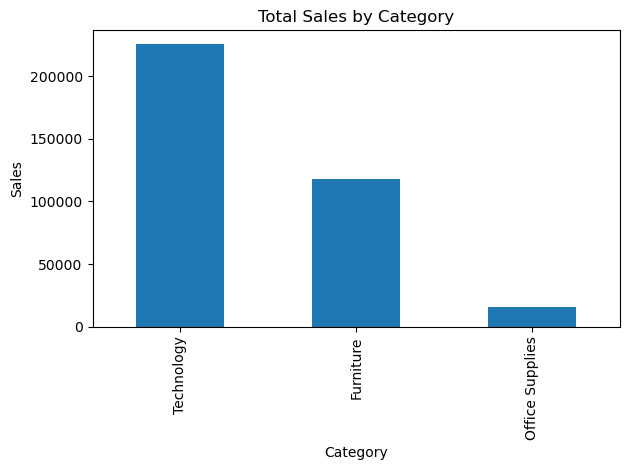

In [27]:
category_summary.plot(x='Category', y='Total_Sales', kind='bar', legend=False, title='Total Sales by Category')
plt.ylabel('Sales')
plt.tight_layout()
plt.show()

## 5. Compare regions

In [30]:
region_summary = sales.groupby('Region', as_index=False).agg(
    Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum')
).sort_values('Total_Profit', ascending=False)
region_summary

,Region,Total_Sales,Total_Profit
3,West,94858.52,10407.87
2,South,105502.36,8654.48
0,Central,84707.09,5182.79
1,East,73721.43,4949.72


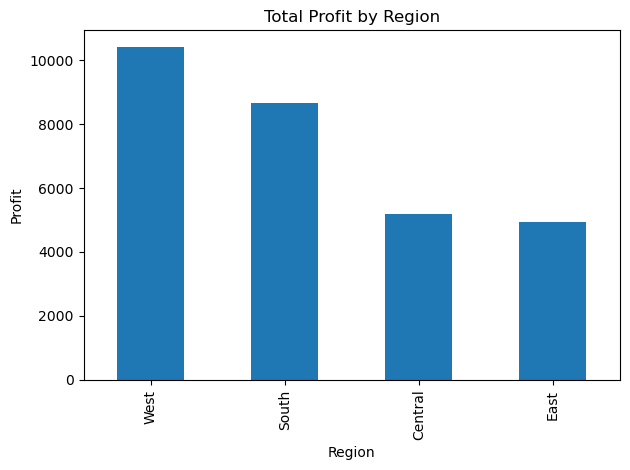

In [32]:
region_summary.plot(x='Region', y='Total_Profit', kind='bar', legend=False, title='Total Profit by Region')
plt.ylabel('Profit')
plt.tight_layout()
plt.show()

## 6. Monthly sales trend

In [35]:
sales['Order_Month'] = sales['Order_Date'].dt.to_period('M').astype(str)
monthly = sales.groupby('Order_Month', as_index=False).agg(
    Total_Sales=('Sales', 'sum'), Total_Profit=('Profit', 'sum')
)
monthly.head()

,Order_Month,Total_Sales,Total_Profit
0,2024-01,23737.08,2645.58
1,2024-02,20665.85,1897.70
2,2024-03,10369.38,1009.58
3,2024-04,17195.97,1220.41
4,2024-05,15150.89,1902.73


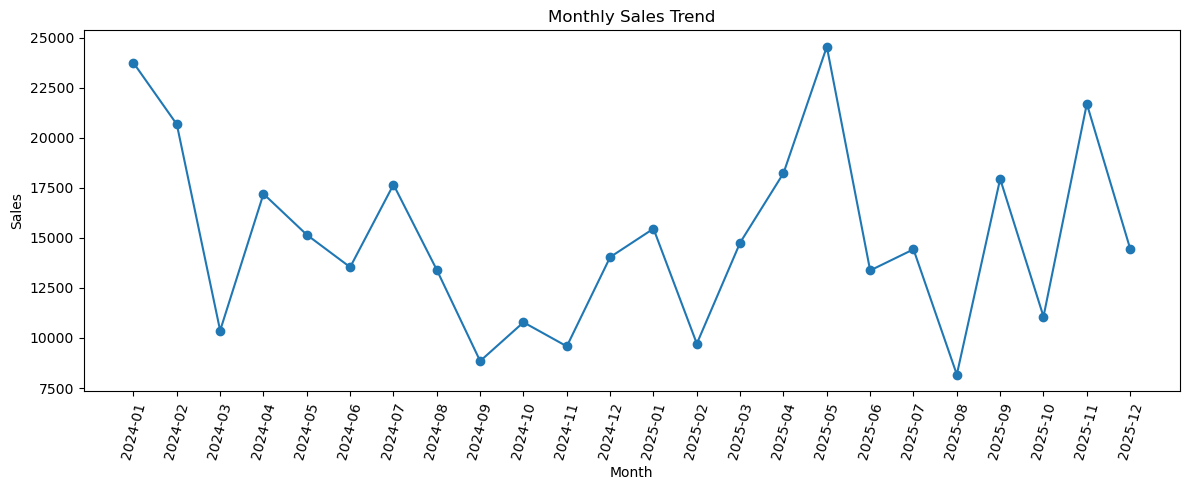

In [37]:
plt.figure(figsize=(12, 5))
plt.plot(monthly['Order_Month'], monthly['Total_Sales'], marker='o')
plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Sales')
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

## 7. Explore discounts and profit

In [40]:
discount_summary = sales.groupby('Discount', as_index=False).agg(
    Average_Profit=('Profit', 'mean'), Order_Lines=('Order_ID', 'count'), Total_Sales=('Sales', 'sum')
)
discount_summary

,Discount,Average_Profit,Order_Lines,Total_Sales
0,0.00,160.105263,133,102571.06
1,0.05,121.573429,70,59185.22
2,0.10,54.100256,78,47437.66
3,0.15,31.210448,67,51174.65
4,0.20,-8.740506,79,46839.94
5,0.30,-85.338356,73,51580.87


## 8. Write business findings

After running the notebook, write 3–5 findings based on the actual outputs. For each finding, include the metric and explain why it matters. Do not assume discounts cause lower profit; this dataset is synthetic and descriptive analysis alone cannot establish causation.

### Finding 1: Technology is the strongest category

Technology generated the highest sales and profit among the three categories. This matters because the business can use category performance to guide inventory planning and marketing decisions.

### Finding 2: Regional profit varies

The West region generated the highest total profit among the four regions. Management should compare regional sales, product mix, and discounts to understand these differences.

### Finding 3: Laptops contribute significantly to sales

Laptops were the leading sub-category by sales and profit in this dataset. The business should monitor demand and inventory for this product group.

### Finding 4: Higher discounts are associated with lower average profit

The average profit was about **$160.11** with no discount and about **-$85.34** with a 30% discount. This is an association in synthetic data and does not prove that discounts alone caused lower profit.

### Finding 5: Overall performance is profitable

Total sales were approximately **$358,789.40** and total profit was **$29,194.86**, giving an overall profit margin of about **8.14%**. Management should track profit margin along with sales to assess business performance.

### Conclusion

Technology and Laptops were important contributors to sales, while the West region led in profit. Reviewing discount practices and regional performance may help identify opportunities to improve profitability. These results are based on synthetic practice data, not a real retailer.